# Challenge 1: datos y análisis exploratorio

Tu primera responsabilidad es preparar una fuente de datos confiable para el proyecto de clasificación de vinos.

**Entrada:** `data/raw/wine.csv`  
**Salidas:** `data/processed/train.csv`, `data/processed/test.csv` y `artifacts/data_contract.json`

> El conjunto de test se crea aquí, pero no debe explorarse ni utilizarse después del split.

## Objetivos

- cargar y validar datos externos;
- identificar problemas básicos de calidad;
- crear un split reproducible y estratificado;
- realizar EDA únicamente sobre entrenamiento;
- guardar datos y metadatos para la siguiente etapa.

In [5]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)

In [6]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga y profiling

In [7]:
DATA_PATH = RAW_DATA_DIR / "wine.csv"
df = pd.read_csv(DATA_PATH)

In [8]:
print("Forma:", df.shape)
print("\nTipos:"); print(df.dtypes.value_counts())
print("\nNulos totales:", int(df.isna().sum().sum()))
print("Duplicados:", int(df.duplicated().sum()))
print("\nDistribución del target:"); print(df["target"].value_counts().sort_index())

Forma: (178, 14)

Tipos:
float64    13
int64       1
Name: count, dtype: int64

Nulos totales: 0
Duplicados: 0

Distribución del target:
target
0    59
1    71
2    48
Name: count, dtype: int64


**Conclusión de calidad:**

No hay nulos ni filas duplicadas, y las 13 variables son numéricas. La clase está razonablemente balanceada (59 / 71 / 48). Por eso no se eliminó ni imputó nada. Sí se decidió hacer un split estratificado para que cada clase mantenga su proporción en train y test.

## 2. Split train/test

In [9]:
train_df, test_df = train_test_split(
    df, test_size=0.2, stratify=df["target"], random_state=RANDOM_STATE
)

In [10]:
# Verificación del split
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (142, 14)
Test: (36, 14)


## 3. EDA sobre entrenamiento

Incluye:

- distribución de clases;
- distribuciones o boxplots de variables relevantes;
- correlaciones;
- tres hallazgos que puedan influir en el modelado.

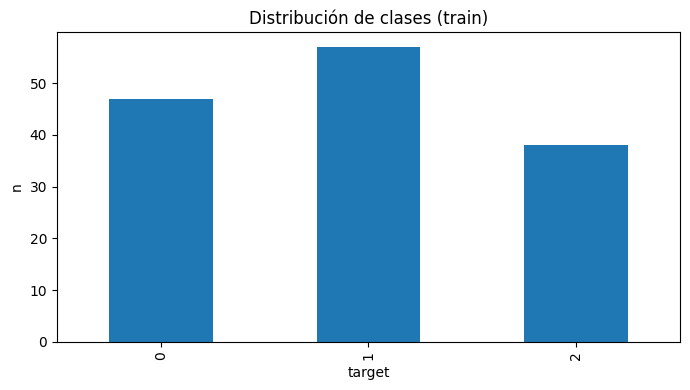

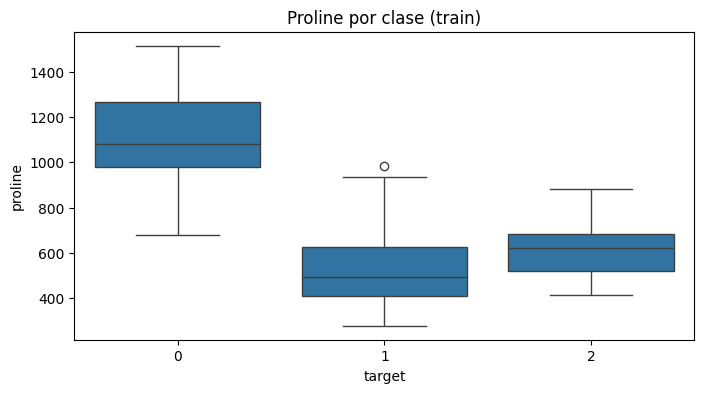

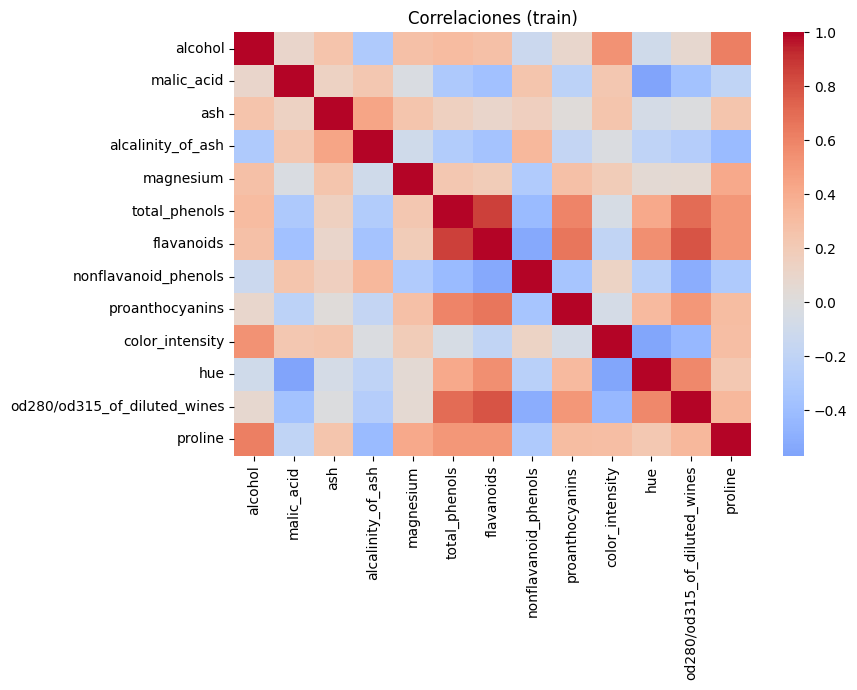

Correlaciones con target (train):
flavanoids                     -0.870
od280/od315_of_diluted_wines   -0.784
total_phenols                  -0.714
proline                        -0.639
hue                            -0.606
alcalinity_of_ash               0.508
proanthocyanins                -0.481
nonflavanoid_phenols            0.477
malic_acid                      0.418
alcohol                        -0.332
color_intensity                 0.269
magnesium                      -0.208
ash                            -0.045
Name: target, dtype: float64


In [11]:
# Solo se usa train_df
counts = train_df["target"].value_counts().sort_index()
counts.plot(kind="bar", title="Distribución de clases (train)")
plt.xlabel("target"); plt.ylabel("n"); plt.tight_layout(); plt.show()

plt.figure(figsize=(8,4))
sns.boxplot(data=train_df, x="target", y="proline"); plt.title("Proline por clase (train)"); plt.show()

plt.figure(figsize=(9,7))
sns.heatmap(train_df.drop(columns="target").corr(), cmap="coolwarm", center=0)
plt.title("Correlaciones (train)"); plt.tight_layout(); plt.show()

print("Correlaciones con target (train):")
print(train_df.corr(numeric_only=True)["target"].drop("target").sort_values(key=abs, ascending=False).round(3))

**Hallazgos:**

1. `flavanoids` (r ≈ −0.87), `od280/od315_of_diluted_wines` (r ≈ −0.78) y `total_phenols` (r ≈ −0.71) son las variables más correlacionadas con el target. Son candidatas fuertes para cualquier modelo.
2. Las escalas difieren mucho: `proline` está en cientos o miles, mientras que `hue` o `ash` están en unidades cercanas a 1. Esto obliga a estandarizar en los modelos sensibles a distancia (KNN) y a los lineales.
3. Hay variables muy correlacionadas entre sí (por ejemplo, `flavanoids` con `total_phenols`). Esto sugiere redundancia, pero con 13 variables y 142 filas no se justifica reducir dimensiones todavía.

## 4. Persistencia de datos y contrato

In [12]:
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
train_df.to_csv(PROCESSED_DATA_DIR / "train.csv", index=False)
test_df.to_csv(PROCESSED_DATA_DIR / "test.csv", index=False)

contract = {
    "target": "target",
    "features": [c for c in df.columns if c != "target"],
    "random_state": RANDOM_STATE,
    "test_size": 0.2,
    "stratify": "target",
}
(ARTIFACTS_DIR / "data_contract.json").write_text(json.dumps(contract, indent=2, ensure_ascii=False), encoding="utf-8")
print("Guardado:", contract["target"], len(contract["features"]), "features")

Guardado: target 13 features


In [13]:
# Verificación de entrega
assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")

Challenge 1 completado.


In [14]:
import zipfile
from google.colab import files

with zipfile.ZipFile("pasos_01.zip", "w") as z:
    z.write("data/processed/train.csv")
    z.write("artifacts/data_contract.json")

files.download("pasos_01.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>